# Tugas Praktikum 4: Association Rule

Nama       : Levina Zahrathul Huda \
NRP        : 5054251033

# Unduh dan Import Dataset

In [1]:
import pandas as pd
import numpy as py
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import fpgrowth, association_rules

In [2]:
df = pd.read_excel("Online Retail.xlsx")

print("Jumlah baris dan kolom:", df.shape)
df.head()
df.info()

Jumlah baris dan kolom: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


# Eksplorasi dan Pembersihan Data

In [3]:
jumlah_baris_sebelum = len(df)
jumlah_invoice_sebelum = df['InvoiceNo'].nunique()

print("Jumlah baris sebelum pembersihan:", jumlah_baris_sebelum)
print("Jumlah invoice sebelum pembersihan:", jumlah_invoice_sebelum)

Jumlah baris sebelum pembersihan: 541909
Jumlah invoice sebelum pembersihan: 25900


In [4]:
df = df.dropna(subset=["Description"])
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[df["Quantity"] > 0]
df["Description"] = df["Description"].str.strip()
df = df[df["Description"] != ""]

In [17]:
jumlah_baris_sesudah = len(df)
jumlah_invoice_sesudah = df['InvoiceNo'].nunique()

print("Jumlah baris sesudah pembersihan:", jumlah_baris_sesudah)
print("Jumlah invoice sesudah pembersihan:", jumlah_invoice_sesudah)

Jumlah baris sesudah pembersihan: 530693
Jumlah invoice sesudah pembersihan: 20136


In [6]:
# Tabel perbandingan sebelum dan sesudah pembersihan
tabel = pd.DataFrame({
    "Keterangan": ["Sebelum Pembersihan", "Sesudah Pembersihan"],
    "Jumlah baris": [
        jumlah_baris_sebelum,
        jumlah_baris_sesudah
    ],
    "Jumlah Invoice": [
        jumlah_invoice_sebelum,
        jumlah_invoice_sesudah
    ]
})

display(tabel)

,Keterangan,Jumlah baris,Jumlah Invoice
0,Sebelum Pembersihan,541909,25900
1,Sesudah Pembersihan,530693,20136


# Persiapan Data untuk Association Rule

In [7]:
basket = df.groupby(
["InvoiceNo", "Description"]
)["Quantity"].sum().unstack(fill_value=0) > 0

basket.head()

Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,returned,taig adjust,test,to push order througha s stock was,website fixed,wrongly coded 20713,wrongly coded 23343,wrongly marked,wrongly marked 23343,wrongly sold (22719) barcode
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [8]:
print("Jumlah baris dan kolom basket:", basket.shape)
print("Jumlah invoice basket:", basket.shape[0])
print("Jumlah produk:", basket.shape[1])

Jumlah baris dan kolom basket: (20136, 4065)
Jumlah invoice basket: 20136
Jumlah produk: 4065


# Penerapan Algoritma

In [9]:
min_support = 0.01
min_confidence = 0.5

print("Min Support:", min_support)
print("Min Confidence:", min_confidence)

Min Support: 0.01
Min Confidence: 0.5


In [10]:
# Algoritma FP-Growth
frequent_itemsets = fpgrowth(
    basket,
    min_support=min_support,
    use_colnames=True
)

frequent_itemsets.sort_values(
    by="support",
    ascending=False
).head(20)

,support,itemsets
0,0.112237,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
92,0.103894,frozenset({JUMBO BAG RED RETROSPOT})
297,0.098778,frozenset({REGENCY CAKESTAND 3 TIER})
587,0.083731,frozenset({PARTY BUNTING})
42,0.077672,frozenset({LUNCH BAG RED RETROSPOT})
7,0.072259,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
617,0.068782,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
43,0.065554,frozenset({PACK OF 72 RETROSPOT CAKE CASES})
174,0.063220,frozenset({LUNCH BAG BLACK SKULL.})
79,0.062028,frozenset({NATURAL SLATE HEART CHALKBOARD})


In [11]:
print("Jumlah frequent itemset:", len(frequent_itemsets))

Jumlah frequent itemset: 1853


In [12]:
# Aturan asosiasi
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=min_confidence
)

print("Jumlah aturan asosiasi:", len(rules))

Jumlah aturan asosiasi: 841


# Evaluasi Aturan Asosiasi

In [18]:
rules_result = rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].copy()

rules_result["antecedents"] = rules_result["antecedents"].apply(
    lambda x: ', '.join(sorted(list(x)))
)

rules_result["consequents"] = rules_result["consequents"].apply(
    lambda x: ', '.join(sorted(list(x)))
)

rules_result = rules_result.sort_values(
    by="lift",
    ascending=False
).reset_index(drop=True)

display(rules_result)

,antecedents,consequents,support,confidence,lift
0,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010081,0.856540,80.219959
1,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010081,0.944186,80.219959
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010081,0.845833,79.961033
3,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010081,0.953052,79.961033
4,HERB MARKER THYME,HERB MARKER ROSEMARY,0.010975,0.932489,78.235865
...,...,...,...,...,...
836,SUKI SHOULDER BAG,JUMBO BAG RED RETROSPOT,0.014005,0.532075,5.121354
837,GREEN REGENCY TEACUP AND SAUCER,REGENCY CAKESTAND 3 TIER,0.025278,0.501478,5.076801
838,TOY TIDY PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.012118,0.520256,5.007587
839,RED RETROSPOT SHOPPER BAG,JUMBO BAG RED RETROSPOT,0.014303,0.500870,4.820989


In [19]:
top_3_rules = rules_result.head(3).copy()
display(top_3_rules)

,antecedents,consequents,support,confidence,lift
0,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010081,0.856540,80.219959
1,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010081,0.944186,80.219959
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010081,0.845833,79.961033


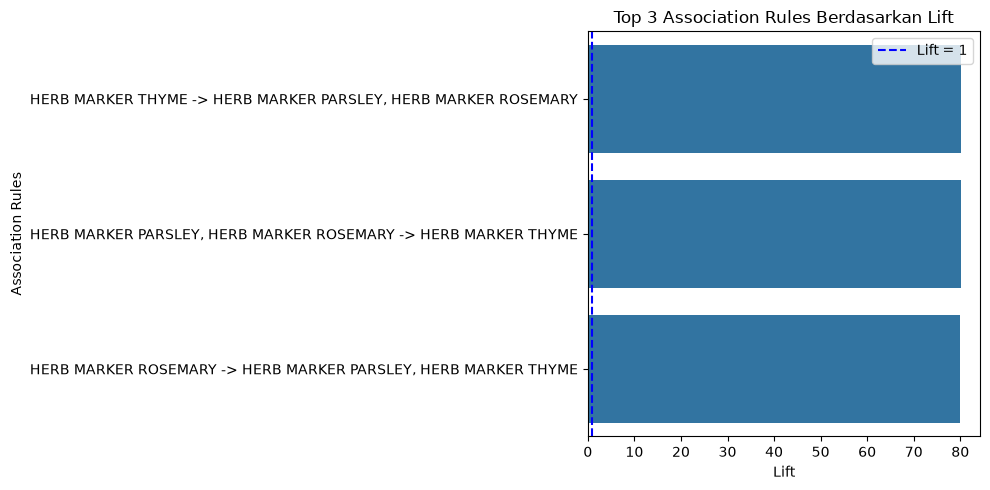

In [20]:
top_3_rules["rule"] = (
    top_3_rules["antecedents"] + " -> " + top_3_rules["consequents"]
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_3_rules,
    x="lift",
    y="rule"
)

plt.axvline(
    x=1,
    color="blue",
    linestyle="--",
    label="Lift = 1"
)

plt.title("Top 3 Association Rules Berdasarkan Lift")
plt.xlabel("Lift")
plt.ylabel("Association Rules")
plt.legend()
plt.tight_layout()
plt.show()

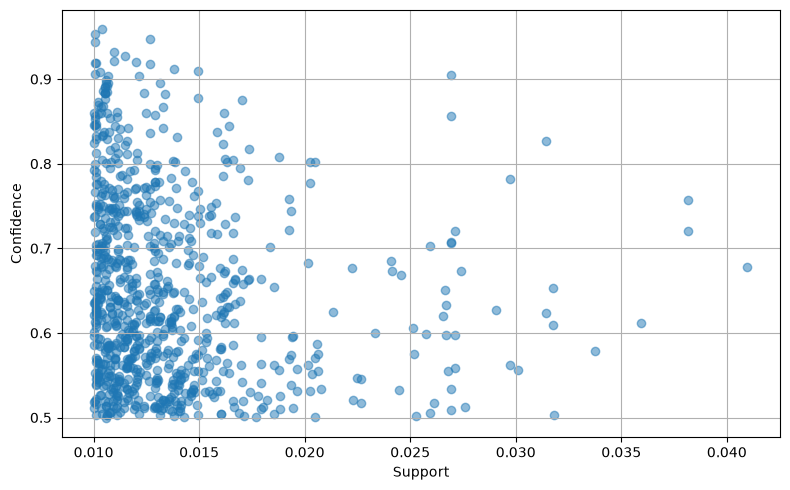

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(
    rules["support"],
    rules["confidence"],
    alpha=0.5
)

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.grid(True)
plt.tight_layout()
plt.show()